# Tutorial 8. A motor-driven pump: three domains in one model

![A motor-driven pump set](../tutorials/images/t08_hero.png)

**Scope:** electromechanical and hydraulic engineering. **Components:** `DCMotor`,
`Gyrator`, `VoltageSource`, `Pipe`, `Tank`, `Atmosphere`, `Housing`, `Ground`.

## The asset

A DC motor drives a gear pump that fills a head tank through a pipe. The machine
is a composite from the library, `DCMotor`: armature resistance and inductance,
the electromechanical coupling, rotor inertia and friction. The gear pump is a
positive-displacement machine: flow is proportional to speed, and torque to the
pressure rise. The questions:

- **Start-up.** How large is the inrush current, how fast does the pump come up to
  speed, and what does the flow do?
- **Operating point.** As the tank fills and the head rises, how do speed, flow
  and current settle, and what is the efficiency from the terminals to the water?

![Multi-domain schematic](../tutorials/images/t08_pd.png)

In Otwin every domain has an across variable (voltage, angular velocity,
pressure) and a through variable (current, torque, flow). A coupling that relates
across to across and through to through is a `Transformer`: the DC machine, whose
back-emf is k·ω and torque k·i. A coupling that relates across to through is a
`Gyrator`: the gear pump, whose flow is D·ω and torque D·Δp.

## Step 1. Build the pump set

In [ ]:
import numpy as np
import pandas as pd
import seaborn as sns

import otwin
from otwin.components.composite import DCMotor
from otwin.components.electrical import Ground, VoltageSource
from otwin.components.hydraulic import Atmosphere, Pipe, Tank
from otwin.components.rotational import Housing
from otwin.components.twoport import Gyrator

sns.set_theme(style="whitegrid", palette=["#201E1D", "#EC3013", "#4D86A6", "#8A8886"])

DISPLACEMENT = 20e-6 / (2 * np.pi)  # m3/rad: 20 cm3 per revolution
supply = VoltageSource(None, name="supply")  # V, an input
motor = DCMotor(
    resistance=0.6,
    inductance=8e-3,
    torque_constant=0.9,
    inertia=0.03,
    friction=5e-4,
    name="motor",
)
gear_pump = Gyrator(
    1 / DISPLACEMENT, domain_1="rotational", domain_2="hydraulic", name="pump"
)
line = Pipe(resistance=5.0e7, name="line")  # Pa s/m3: a long small-bore line
tank = Tank(0.25, level=0.2, base_elevation=4.0, name="tank")  # m2, m, m above the pump
atm = Atmosphere(name="atm")
housing = Housing(name="housing")
gnd = Ground(name="gnd")

pump_set = gnd >> supply >> motor >> gnd
pump_set.connect(motor.shaft, gear_pump.p1)
pump_set.connect(gear_pump.p2, line.a)
pump_set.connect(line.b, tank.port)
pump_set.connect(gear_pump.n1, housing.port)
pump_set.connect(gear_pump.n2, atm.port)
model = otwin.compile(pump_set)
print(model.summary())

System: system

Components:
  gnd                          ground [any]
  supply                       voltage_source [electrical]
  motor.armature_resistance    resistor [electrical]
  motor.armature               inductor [electrical]
  motor.coupling               transformer [electrical]
  motor.rotor                  inertia [rotational]
  motor.bearing                rotational_damper [rotational]
  motor.housing                housing [any]
  pump                         gyrator [rotational]
  line                         pipe [hydraulic]
  tank                         tank [hydraulic]
  housing                      housing [any]
  atm                          atmosphere [any]

States:
  motor.armature.flux          flux linkage [Wb]  x0 = 0
  motor.rotor.angular_momentum angular momentum [kg m^2/s]  x0 = 0
  tank.volume                  volume [m^3]  x0 = 0.05

Inputs:
  supply                       voltage [V]

Parameters:
  motor.armature_resistance.resistance 0.6          oh

Three states: the armature flux, the rotor momentum and the tank volume. The
gyrator adds none. Note the port names of the two-port: `p1`, `n1` on the
rotational side and `p2`, `n2` on the hydraulic side; the `n` ports are the
references of each side (the housing and the atmosphere), each in its own domain.

## Step 2. Start-up

Apply 200 V at t = 0.05 s and watch the first two seconds with a fine step: the
electrical time constant L/R is 13 ms.

In [ ]:
t = np.arange(0.0, 2.0, 2e-4)
run = model.simulate(
    t=t, inputs={"supply": lambda time: 200.0 if time >= 0.05 else 0.0}, solver="rk4"
)
i = run["motor.armature.current"]
w = run["motor.rotor.angular_velocity"]
q = -run[
    "pump.side2.flow"
]  # flow leaving the pump: side-2 through is counted into the port
print(
    f"inrush current {i.max():.0f} A, steady {i[-1]:.1f} A; stall current would be {200 / 0.6:.0f} A"
)
print(
    f"speed settles at {w[-1] * 60 / 2 / np.pi:.0f} rpm, no-load speed U/k = {200 / 0.9 * 60 / 2 / np.pi:.0f} rpm"
)
print(
    f"flow {q[-1] * 1e3 * 60:.1f} L/min = D w = {DISPLACEMENT * w[-1] * 1e3 * 60:.1f} L/min; "
    f"pressure at the pump {run['pump.side2.pressure'][-1] / 1e5:.2f} bar"
)
time_63 = t[np.flatnonzero(w >= 0.63 * w[-1])[0]] - 0.05
print(f"mechanical time constant about {time_63 * 1e3:.0f} ms")

inrush current 207 A, steady 0.4 A; stall current would be 333 A
speed settles at 2120 rpm, no-load speed U/k = 2122 rpm
flow 42.4 L/min = D w = 42.4 L/min; pressure at the pump 0.77 bar
mechanical time constant about 29 ms


The current spikes toward the stall value before the back-emf builds, then falls
to the value that carries the pump torque and the friction. The speed is below
the no-load value by the drop I·R over k. The flow is exactly D·ω: the gyrator is
an identity the compiler enforces. (The two-port's side-2 through variable is
counted into its port, so the flow the pump delivers is its negative.)

## Step 3. Plot the start-up

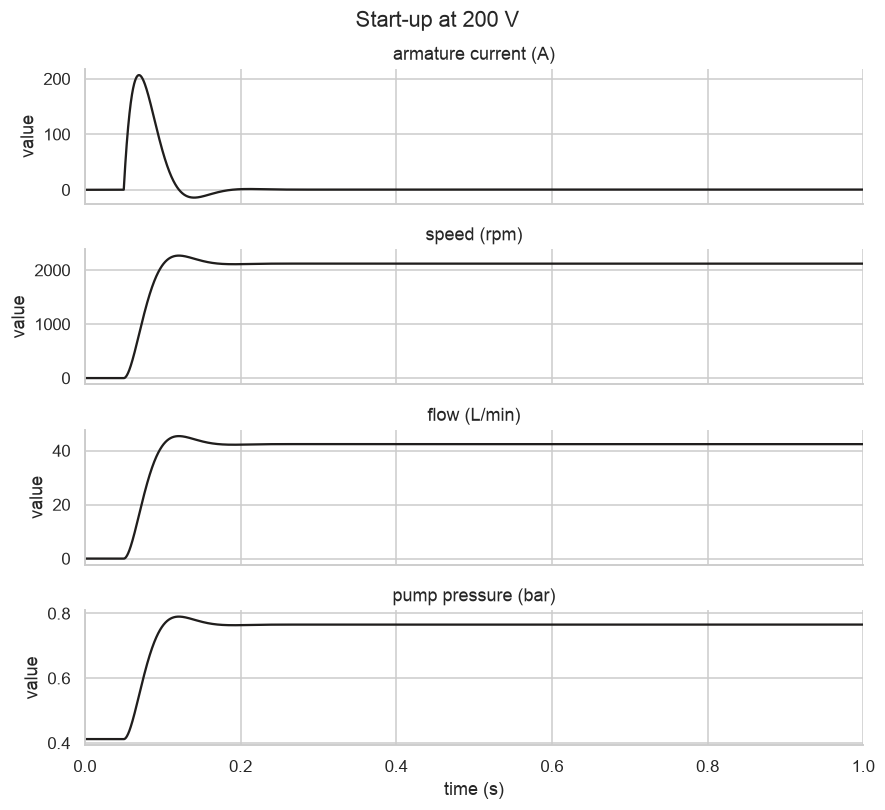

In [ ]:
frame = pd.DataFrame(
    {
        "time (s)": t,
        "armature current (A)": i,
        "speed (rpm)": w * 60 / 2 / np.pi,
        "flow (L/min)": q * 6e4,
        "pump pressure (bar)": run["pump.side2.pressure"] / 1e5,
    }
)
long = frame.melt("time (s)", var_name="signal", value_name="value")
g = sns.relplot(
    data=long,
    x="time (s)",
    y="value",
    row="signal",
    kind="line",
    height=1.8,
    aspect=4.5,
    facet_kws={"sharey": False},
    color="#201E1D",
)
g.set_titles("{row_name}")
g.set(xlim=(0, 1.0))
g.figure.suptitle("Start-up at 200 V", y=1.02)

## Step 4. Filling the tank

Run ten minutes. As the level rises the head grows, the pump pressure rises, the
torque rises, and the motor slows a little. The flow falls with the speed. Read
the efficiency from the terminals to the hydraulic power at the pump.

In [ ]:
t_long = np.arange(0.0, 600.0, 0.05)
fill = model.simulate(t=t_long, inputs={"supply": 200.0}, solver="midpoint")
q_fill = -fill["pump.side2.flow"]
p_el = np.abs(fill["supply.power"])
p_hyd = fill["pump.side2.pressure"] * q_fill
p_cu = fill["motor.armature_resistance.power"]
p_fric = fill["motor.bearing.power"]
k = -1
print(
    f"after 10 min: level {fill['tank.level'][k]:.2f} m, speed {fill['motor.rotor.angular_velocity'][k] * 60 / 2 / np.pi:.0f} rpm, "
    f"flow {q_fill[k] * 6e4:.1f} L/min"
)
print(
    f"electrical in {p_el[k]:.0f} W, copper loss {p_cu[k]:.0f} W, friction {p_fric[k]:.0f} W, "
    f"hydraulic at the pump {p_hyd[k]:.0f} W -> efficiency {p_hyd[k] / p_el[k]:.0%}"
)
print(
    f"of the hydraulic power, {fill['line.power'][k]:.0f} W is lost in the line and {fill['tank.pressure'][k] * q_fill[k]:.0f} W lifts water "
    f"(static head {fill['tank.pressure'][k] / 1e5:.2f} bar)"
)

after 10 min: level 1.90 m, speed 2119 rpm, flow 42.4 L/min
electrical in 91 W, copper loss 0 W, friction 25 W, hydraulic at the pump 66 W -> efficiency 73%
of the hydraulic power, 25 W is lost in the line and 41 W lifts water (static head 0.58 bar)


The balance closes: electrical power in equals copper loss plus friction plus
hydraulic power, and the hydraulic power splits between the line loss and the
useful lift into the tank. Every term is an output by name.

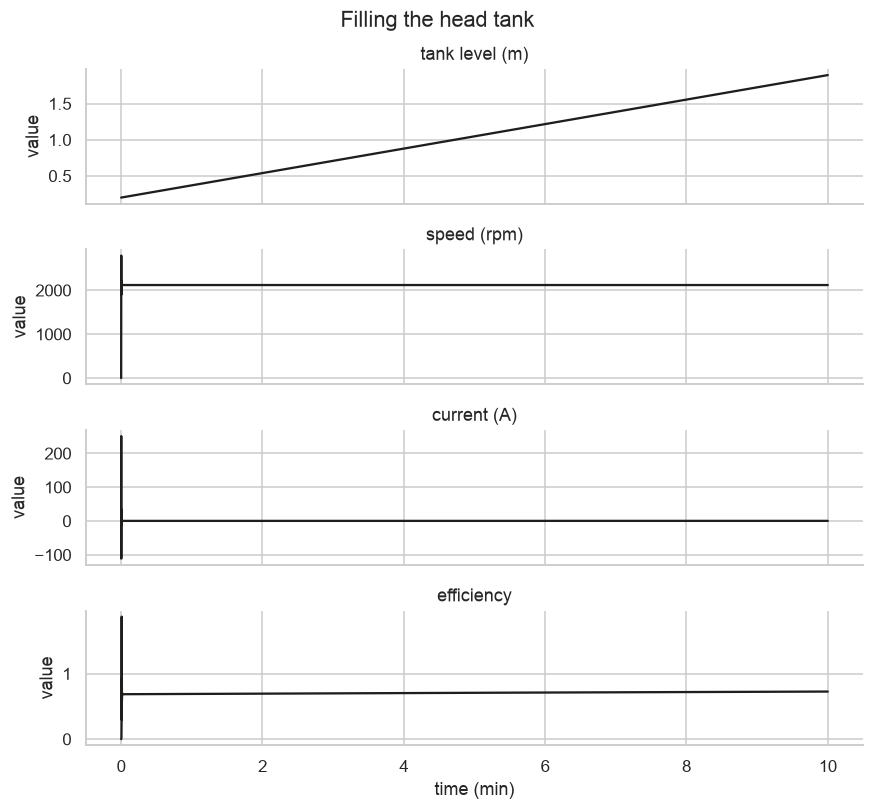

In [ ]:
frame = pd.DataFrame(
    {
        "time (min)": t_long / 60,
        "tank level (m)": fill["tank.level"],
        "speed (rpm)": fill["motor.rotor.angular_velocity"] * 60 / 2 / np.pi,
        "current (A)": fill["motor.armature.current"],
        "efficiency": p_hyd / p_el,
    }
)
long = frame.melt("time (min)", var_name="signal", value_name="value")
g = sns.relplot(
    data=long,
    x="time (min)",
    y="value",
    row="signal",
    kind="line",
    height=1.8,
    aspect=4.5,
    facet_kws={"sharey": False},
    color="#201E1D",
)
g.set_titles("{row_name}")
g.figure.suptitle("Filling the head tank", y=1.02)

## Step 5. The two couplings, checked

Two identities should hold to round-off at every step: the motor's torque equals
k times its current, and the pump's flow equals D times its speed.

In [ ]:
tau = fill["motor.coupling.side2.torque"]
print(
    f"max |tau - k i| = {np.max(np.abs(np.abs(tau) - 0.9 * np.abs(fill['motor.armature.current']))):.2e} N m"
)
print(
    f"max |Q - D w| = {np.max(np.abs(q_fill - DISPLACEMENT * fill['motor.rotor.angular_velocity'])):.2e} m3/s"
)

max |tau - k i| = 2.84e-14 N m
max |Q - D w| = 1.08e-19 m3/s


Both hold exactly. That is the point of putting couplings in the structure
rather than writing them as equations: they cannot drift.

## What to take from this

- Three domains, one model, no hand-written coupling equations: a `DCMotor`
  composite and a `Gyrator`.
- Transformer or gyrator is decided by what the device relates: across to across
  (machine), or across to through (positive-displacement pump, piston).
- Power is accounted at every port, so efficiency chains are a few lookups.

Next: [Tutorial 9](09_flywheel_storage.md) builds a device from the fundamental
elements alone.